In [9]:
!pip install -q stable-baselines3 huggingface_hub gymnasium[classic-control]

In [27]:
from stable_baselines3 import PPO
from huggingface_sb3 import load_from_hub
import gymnasium as gym
import numpy as np
import torch as th
from IPython.display import HTML
import matplotlib.animation as animation
import matplotlib.pyplot as plt

In [11]:
checkpoint = load_from_hub(repo_id="ThomasSimonini/ppo-LunarLander-v2", filename="ppo-LunarLander-v2.zip")
model = PPO.load(checkpoint)

/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/save_util.py:165: DeprecationWarning: numpy.core.numeric is deprecated and has been renamed to numpy._core.numeric. The numpy._core namespace contains private NumPy internals and its use is discouraged, as NumPy internals can change without warning in any release. In practice, most real-world usage of numpy.core is to access functionality in the public NumPy API. If that is the case, use the public NumPy API. If not, you are using NumPy internals. If you would still like to access an internal attribute, use numpy._core.numeric._frombuffer.
  deserialized_object = cloudpickle.loads(base64_object)
/usr/local/lib/python3.13/dist-packages/stable_baselines3/common/save_util.py:167: UserWarning: Could not deserialize object clip_range. Consider using `custom_objects` argument to replace this object.
Exception: code() argument 13 must be str, not int
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/stable_baselines3/comm

In [21]:
env = gym.make("LunarLander-v3", render_mode="rgb_array")

In [43]:
obs, info = env.reset(seed=42)
images = []
total_reward = 0
cumulative_rewards = []

for step in range(1000):
    action, _states = model.predict(obs, deterministic=True)
    obs, reward, terminated, truncated, info = env.step(action)
    total_reward += reward
    cumulative_rewards.append(total_reward)
    img = env.render()
    images.append((img, total_reward))
    if terminated or truncated:
        print(f"Епізод завершено за {step} кроків. Загальна нагорода: {total_reward}")
        break

env.close()

Епізод завершено за 90 кроків. Загальна нагорода: -98.51148172367904


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


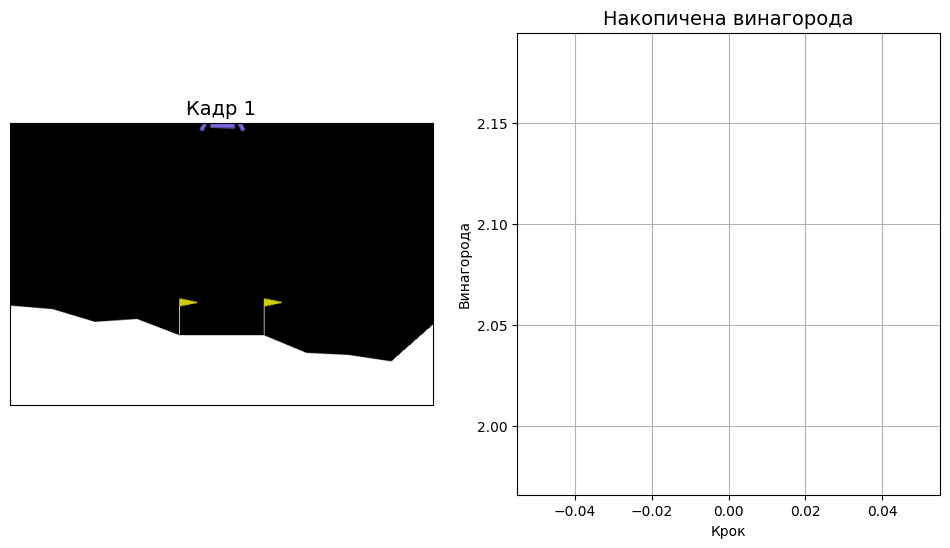

In [44]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))
def animate(i):
 img, total_reward = images[i]
 ax1.clear()
 ax1.imshow(img)
 ax1.set_xticks([])
 ax1.set_yticks([])
 ax1.set_title(f"Кадр {i+1}", fontsize=14)
 ax2.clear()
 ax2.plot(cumulative_rewards[:i+1], color='blue')
 ax2.set_title("Накопичена винагорода", fontsize=14)
 ax2.set_xlabel("Крок")
 ax2.set_ylabel("Винагорода")
 ax2.grid(True)
ani = animation.FuncAnimation(fig, animate, frames=len(images), interval=50)
# візуал
HTML(ani.to_jshtml())